# Notebook 01 - Analyse Exploratoire des Données (EDA)

## Analyse des données patients atteints de cancer
Description

Cette activité pratique se concentre sur la compréhension approfondie des données des patients atteints de cancer, un élément crucial pour élucider les mécanismes de la maladie, identifier les facteurs de risque et guider les décisions cliniques. L’objectif de cette étude est d’explorer les données afin de personnaliser les traitements, améliorer les pronostics et optimiser la prise en charge des patients.

Le dataset utilisé permet d’analyser les facteurs de risque tels que l’obésité, le tabagisme, les prédispositions génétiques, ainsi que le niveau de prédiction du cancer chez les patients. Ces données peuvent être exploitées pour :

Des analyses de santé publique

Des recherches médicales

Des applications cliniques visant à améliorer la prévention et le suivi des maladies
Attributs du dataset

PatientID : Identifiant unique de chaque patient.

first_name : Prénom du patient.

last_name : Nom de famille du patient.

BirthDate : Date de naissance du patient.

gender : Sexe du patient (homme, femme, autre).

Obesity : Indicateur d’obésité (oui/non).

Smoking : Indicateur de tabagisme (oui/non).

Genetic Risk : Mesure du risque génétique associé à une maladie spécifique ou à un ensemble de maladies.

Cancer Prediction Level : Niveau de prédiction du risque de cancer pour chaque patient.

Ce projet permet de visualiser, analyser et interpréter les données pour mieux comprendre les facteurs de risque et soutenir les décisions cliniques.

## Objectifs
1. Analyse descriptive des données
2. Visualisations (minimum 5 types différents)
3. Analyse des corrélations
4. Détection des problèmes dans les données

Dataset:Cance_Pediction_Dataset.csv



In [2]:
#Importation des modules système
import sys
import os
sys.path.append('../')
sys.path.append(r"C:\Users\DELL\Music\project")

# Ajouter le dossier utils au path (si nécessaire)
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../utils")))

# Importation des bibliothèques de traitement et de visualisation des données
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Chargement du jeu de données
data_path = r'C:\Users\DELL\Music/project/ data/Cance_Pediction_Dataset.csv'
df = pd.read_csv(data_path)

#Gestion des avertissements
import warnings
warnings.filterwarnings('ignore')

In [3]:

%matplotlib inline
%matplotlib inline
    
 #Séparation des données en ensembles d’entraînement et de test   
from sklearn.model_selection import train_test_split
# Traitement des valeurs manquantes
from sklearn.impute import SimpleImputer

#Ces fonctionstransforment les variables qualitatives en valeurs numériques
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

#Sélection des caractéristiques pertinentes
from sklearn.feature_selection import SelectKBest

#Importation des modèles de classification supervisée 
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

#Méthodes d’ensemble (Ensemble Learning)
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier

#Évaluation et validation des modèles
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

#Ces métriques permettent d’évaluer les performances du modèle :
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

#Importation d’une fonction de prétraitement personnalisée
from preprocessing import remove_outliers


In [4]:
df = pd.read_csv(r"C:\Users\DELL\Music/project/ data/Cance_Pediction_Dataset.csv")

In [5]:

# Ajouter le dossier racine du projet au path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(PROJECT_ROOT)

In [6]:
from utils.visualization import plot_distributions, plot_correlation_matrix, plot_confusion_matrix, plot_roc_curve


In [7]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [8]:
sns.set(style='darkgrid')

## 1.Analyse descriptive des données

In [9]:
#Affiche le nombre de lignes et de colonnes de la dataset.
print(df.shape)

(1000, 9)


In [10]:
#affiche les 5 premières lignes
df.head() 

,PatientID,first_name,last_name,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level
0,1.0,Marlee,Merrgen,7/29/2011,Homme,Obésité de classe II,Yes,NaN,Medium
1,2.0,Heinrik,Baelde,9/25/1992,Male,Obésité de classe II,No,Yes,Medium
2,3.0,NaN,Duffyn,5/10/1950,Homme,Poids normal Surpoids,Yes,Maybe,Low
3,4.0,Ninette,Checchetelli,3/21/2007,Homme,Obésité de classe I,Yes,No,Low
4,5.0,Neala,Dible,7/10/2006,Femme,Obesité exteme,No,Maybe,Medium


In [11]:
#Informations générales
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   PatientID                978 non-null    float64
 1   first_name               969 non-null    object 
 2   last_name                1000 non-null   object 
 3   BirthDate                1000 non-null   object 
 4   gender                   980 non-null    object 
 5   Obesity                  1000 non-null   object 
 6   Smoking                  1000 non-null   object 
 7   Genetic Risk             962 non-null    object 
 8   Cancer Prediction Level  962 non-null    object 
dtypes: float64(1), object(8)
memory usage: 70.4+ KB
None


In [12]:
print("\nValeurs manquantes :")
print(df.isnull().sum())



Valeurs manquantes :
PatientID                  22
first_name                 31
last_name                   0
BirthDate                   0
gender                     20
Obesity                     0
Smoking                     0
Genetic Risk               38
Cancer Prediction Level    38
dtype: int64


In [13]:
#Analyse descriptive des données
df.describe()

,PatientID
count,978.000000
mean,499.641104
std,289.330383
min,1.000000
25%,248.250000
50%,499.500000
75%,749.750000
max,1000.000000


In [14]:
#voir les colonnes de DataFrame df
print(df.columns)

Index(['PatientID', 'first_name', 'last_name', 'BirthDate', 'gender',
       'Obesity', 'Smoking', 'Genetic Risk', 'Cancer Prediction Level'],
      dtype='object')


In [15]:
#afficher les colonnes
list(df.columns)

['PatientID',
 'first_name',
 'last_name',
 'BirthDate',
 'gender',
 'Obesity',
 'Smoking',
 'Genetic Risk',
 'Cancer Prediction Level']

In [16]:
#Affichage d’un échantillon aléatoire des données
print(df.sample())

     PatientID first_name last_name BirthDate gender                Obesity  \
102      103.0      Uriah     Teers  9/4/1969   Male  Obésité de classe III   

    Smoking Genetic Risk Cancer Prediction Level  
102     Yes           No                     Low  


In [17]:
# Afficher les dernières lignes
df.tail( )

,PatientID,first_name,last_name,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level
995,996.0,Luke,Mongeot,9/7/1937,H,Obésité de classe III,No,Yes,Medium
996,997.0,Fran,Stoggell,8/5/1943,Femme,Sous-poids,No,No,High
997,998.0,Jase,Paaso,6/8/1963,H,Poids normal Surpoids,Yes,Yes,High
998,999.0,Charlot,Woolis,9/13/1940,Femme,Obésité de classe I,Yes,Maybe,High
999,1000.0,Sherrie,Skett,10/30/1984,Femme,Obésité de classe III,Yes,No,Low


In [18]:
#Ces fonctions permettent de détecter les valeurs manquantes dans la dataset.
print(df.isnull().sum())

PatientID                  22
first_name                 31
last_name                   0
BirthDate                   0
gender                     20
Obesity                     0
Smoking                     0
Genetic Risk               38
Cancer Prediction Level    38
dtype: int64


In [19]:
#Vérifier doublons
print(df.duplicated().sum())

0


In [20]:
#supprime des colonnes du DataFrame.
df = df.drop(columns=['first_name', 'last_name'])


In [21]:
#Convertir les colonnes Yes/No en 1/0
# Exemple pour Obesity et Smoking
binary_cols = ['Obesity', 'Smoking']
for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({'Yes': 1, 'No': 0})


In [22]:
#Convertir les colonnes catégorielles avec plusieurs valeurs en nombres (Label Encoding)
from sklearn.preprocessing import LabelEncoder

multi_cat_cols = ['gender', 'Genetic Risk', 'Cancer Prediction Level']

le = LabelEncoder()
for col in multi_cat_cols:
    if col in df.columns:
        df[col] = le.fit_transform(df[col].astype(str))


In [23]:
#Convertir la date de naissance en âge (numérique)
from datetime import datetime

if 'BirthDate' in df.columns:
    df['BirthDate'] = pd.to_datetime(df['BirthDate'], errors='coerce')
    today = pd.to_datetime('today')
    df['Age'] = (today - df['BirthDate']).dt.days / 365.25  # âge en années décimales


In [24]:
#Afficher les valeurs nulles
df.isnull()

,PatientID,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level,Age
0,False,False,False,True,False,False,False,False
1,False,False,False,True,False,False,False,False
2,False,False,False,True,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...
995,False,False,False,True,False,False,False,False
996,False,False,False,True,False,False,False,False
997,False,False,False,True,False,False,False,False
998,False,False,False,True,False,False,False,False


In [25]:
#affiche le type de données (datatype) de chaque colonne d’un DataFrame pandas.
print(df.dtypes)

PatientID                         float64
BirthDate                  datetime64[ns]
gender                              int64
Obesity                           float64
Smoking                             int64
Genetic Risk                        int64
Cancer Prediction Level             int64
Age                               float64
dtype: object


In [26]:
#Suppression des valeurs nulles
df.dropna()

,PatientID,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level,Age


In [27]:
#affiche toutes les valeurs distinctes (uniques) présentes dans la colonne gender du DataFrame.
print(df['gender'].unique())

[4 5 2 0 3 1 6]


In [28]:
#affiche Une ligne par PatientID
#affiche Les moyennes de toutes les colonnes numériques pour chaque patient
grouped_df = df.groupby('PatientID').mean()
print(grouped_df)

           BirthDate  gender  Obesity  Smoking  Genetic Risk  \
PatientID                                                      
1.0       2011-07-29     4.0      NaN      1.0           3.0   
2.0       1992-09-25     5.0      NaN      0.0           2.0   
3.0       1950-05-10     4.0      NaN      1.0           0.0   
4.0       2007-03-21     4.0      NaN      1.0           1.0   
5.0       2006-07-10     2.0      NaN      0.0           0.0   
...              ...     ...      ...      ...           ...   
996.0     1937-09-07     3.0      NaN      0.0           2.0   
997.0     1943-08-05     2.0      NaN      0.0           1.0   
998.0     1963-06-08     3.0      NaN      1.0           2.0   
999.0     1940-09-13     2.0      NaN      1.0           0.0   
1000.0    1984-10-30     2.0      NaN      1.0           1.0   

           Cancer Prediction Level        Age  
PatientID                                      
1.0                            2.0  14.466804  
2.0                    

Profilage des données avec visualisation

## 2. Visualisations (minimum 5 types différents)

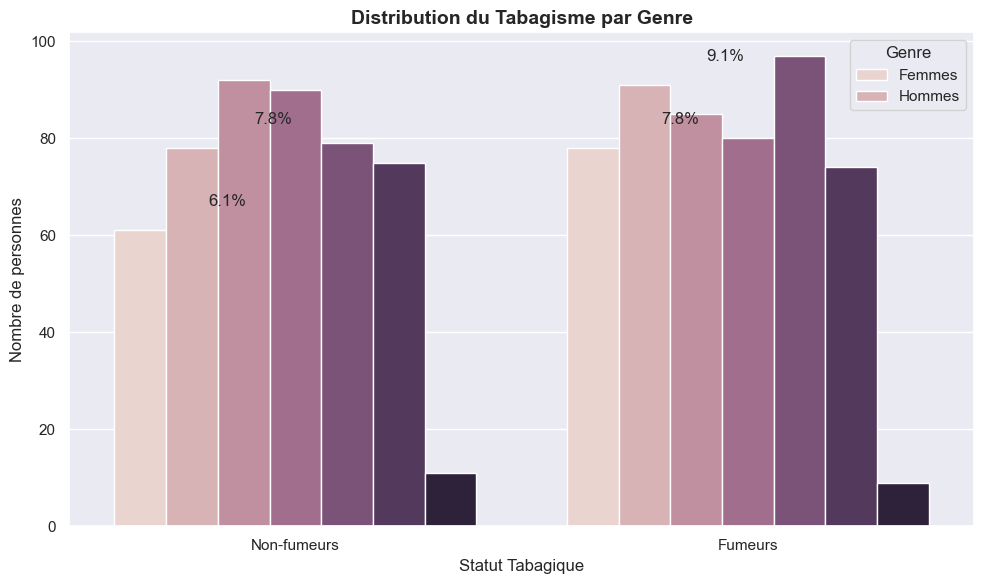

In [29]:
# # graphique à barres
plt.figure(figsize=(10, 6))

sns.countplot(x='Smoking', hue='gender', data=df)

plt.title('Distribution du Tabagisme par Genre', fontsize=14, fontweight='bold')
plt.xlabel('Statut Tabagique', fontsize=12)
plt.ylabel('Nombre de personnes', fontsize=12)

# Remplacer les labels numériques
plt.xticks([0, 1], ['Non-fumeurs', 'Fumeurs'])
plt.legend(['Femmes', 'Hommes'], title='Genre')

# Ajouter les pourcentages
total = len(df)
for i, smoking_status in enumerate([0, 1]):
    for j, gender_val in enumerate([0, 1]):
        count = len(df[(df['Smoking'] == smoking_status) & (df['gender'] == gender_val)])
        percentage = (count / total) * 100
        plt.text(i + j*0.1 - 0.15, count + 5, f'{percentage:.1f}%', ha='center')

plt.tight_layout()
plt.show()


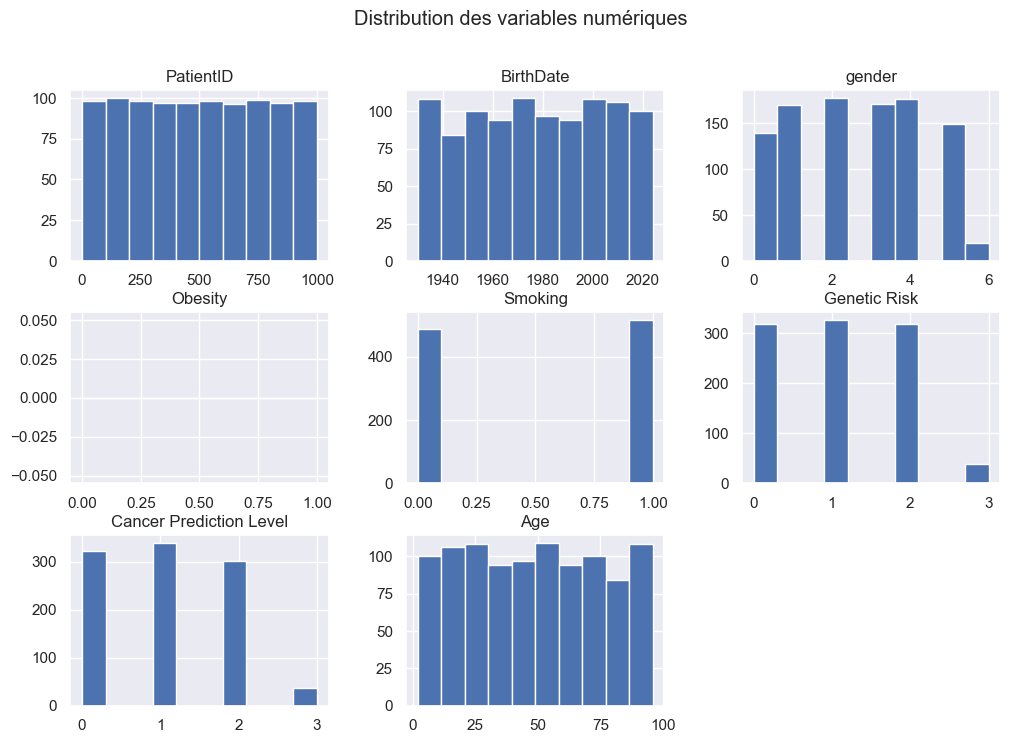

In [31]:
# Visualisation Histogrammes des variables numériques
df.hist(figsize=(12, 8))
plt.suptitle("Distribution des variables numériques")
plt.show()


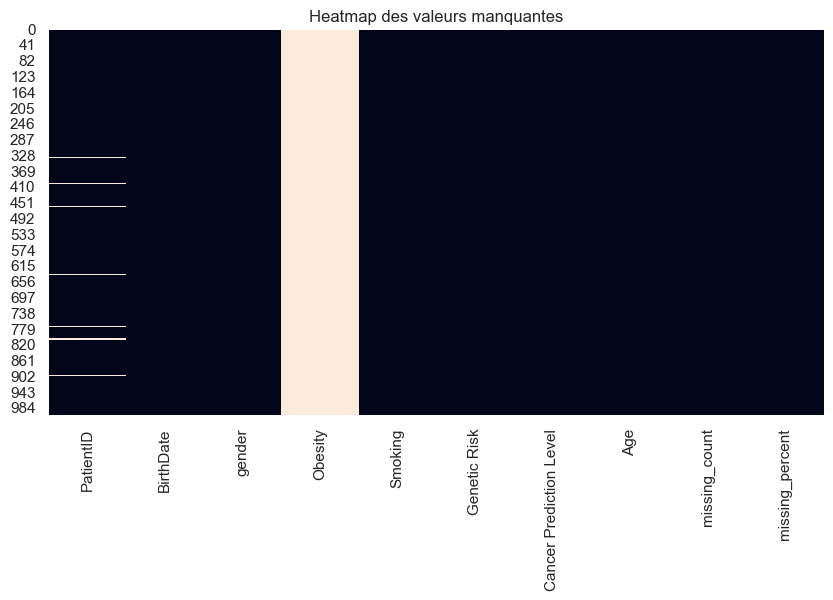

In [34]:
# Visualisation Heatmap des valeurs manquantes
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Heatmap des valeurs manquantes")
plt.show()


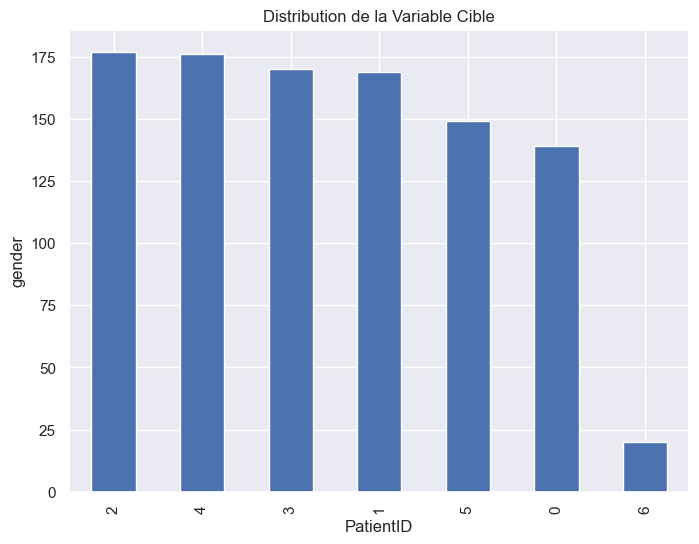

In [35]:
# Visualisation  Histoogramme: Distribution de la variable cible
plt.figure(figsize=(8, 6))
df['gender'].value_counts().plot(kind='bar')
plt.title('Distribution de la Variable Cible')
plt.xlabel('PatientID')
plt.ylabel('gender')
plt.show()

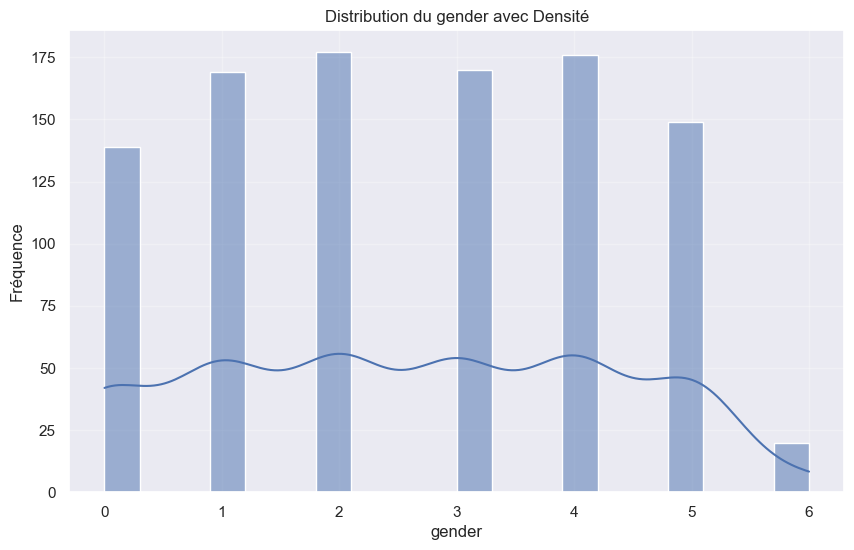

In [37]:
# Visualisation
# Avec seaborn pour un meilleur rendu
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.histplot(df['gender'], kde=True, bins=20)
plt.title('Distribution du gender avec Densité')
plt.xlabel('gender')
plt.ylabel('Fréquence')
plt.grid(True, alpha=0.3)
plt.show()

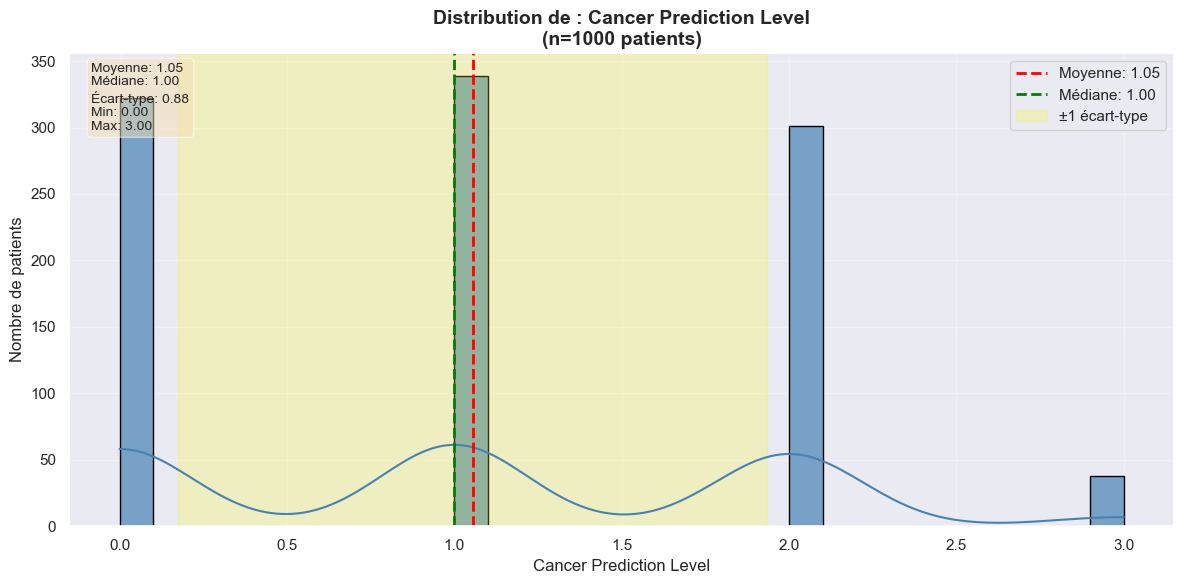

In [70]:
#Histogramme avec Courbe de Densité (KDE)
plt.figure(figsize=(12, 6))

# Histogramme avec plus de détails
sns.histplot(data=df, x=col, kde=True, bins=30, 
             color='steelblue', alpha=0.7, edgecolor='black')

# Ajouter statistiques
mean_val = df[col].mean()
median_val = df[col].median()
std_val = df[col].std()

plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, 
            label=f'Moyenne: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='--', linewidth=2, 
            label=f'Médiane: {median_val:.2f}')

# Zone d'écart-type
plt.axvspan(mean_val - std_val, mean_val + std_val, 
            alpha=0.2, color='yellow', label='±1 écart-type')

plt.title(f'Distribution de : {col}\n(n={len(df)} patients)', 
          fontsize=14, fontweight='bold')
plt.xlabel(col, fontsize=12)
plt.ylabel('Nombre de patients', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)

# Ajouter des statistiques dans un coin
stats_text = f"Moyenne: {mean_val:.2f}\nMédiane: {median_val:.2f}\nÉcart-type: {std_val:.2f}\nMin: {df[col].min():.2f}\nMax: {df[col].max():.2f}"
plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes,
         verticalalignment='top', fontsize=10,
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

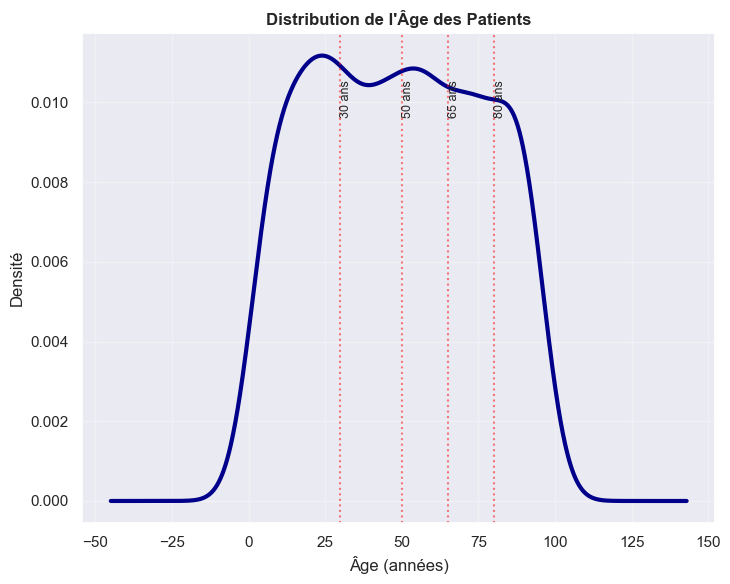

In [73]:
# Simulation d'une analyse d'Âge réaliste
if 'Age' in df.columns:
    plt.figure(figsize=(14, 6))
    
    # Sous-graphique 1 : Densité simple
    plt.subplot(1, 2, 1)
    df['Age'].plot(kind='density', linewidth=3, color='darkblue')
    plt.title('Distribution de l\'Âge des Patients', fontweight='bold')
    plt.xlabel('Âge (années)')
    plt.ylabel('Densité')
    plt.grid(alpha=0.3)
    
    # Ajouter des repères d'âge
    important_ages = [30, 50, 65, 80]  # Âges clés pour le cancer
    for age in important_ages:
        plt.axvline(age, color='red', linestyle=':', alpha=0.5)
        plt.text(age, plt.ylim()[1]*0.9, f'{age} ans', 
                 rotation=90, verticalalignment='top', fontsize=9)
    
    # Si vous avez une variable de risque
    if 'Cancer_Risk' in df.columns:
        # Créer des groupes de risque
        df['Risk_Group'] = pd.cut(df['Cancer_Risk'], 
                                  bins=[0, 0.3, 0.7, 1],
                                  labels=['Faible', 'Moyen', 'Élevé'])
        
        colors = ['green', 'orange', 'red']
        for i, group in enumerate(['Faible', 'Moyen', 'Élevé']):
            if group in df['Risk_Group'].unique():
                subset = df[df['Risk_Group'] == group]['Age'].dropna()
                subset.plot(kind='density', linewidth=2, 
                           color=colors[i], label=f'Risque {group}')
        
        plt.title('Âge par Niveau de Risque', fontweight='bold')
        plt.xlabel('Âge (années)')
        plt.ylabel('Densité')
        plt.legend(title='Risque Cancer')
        plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

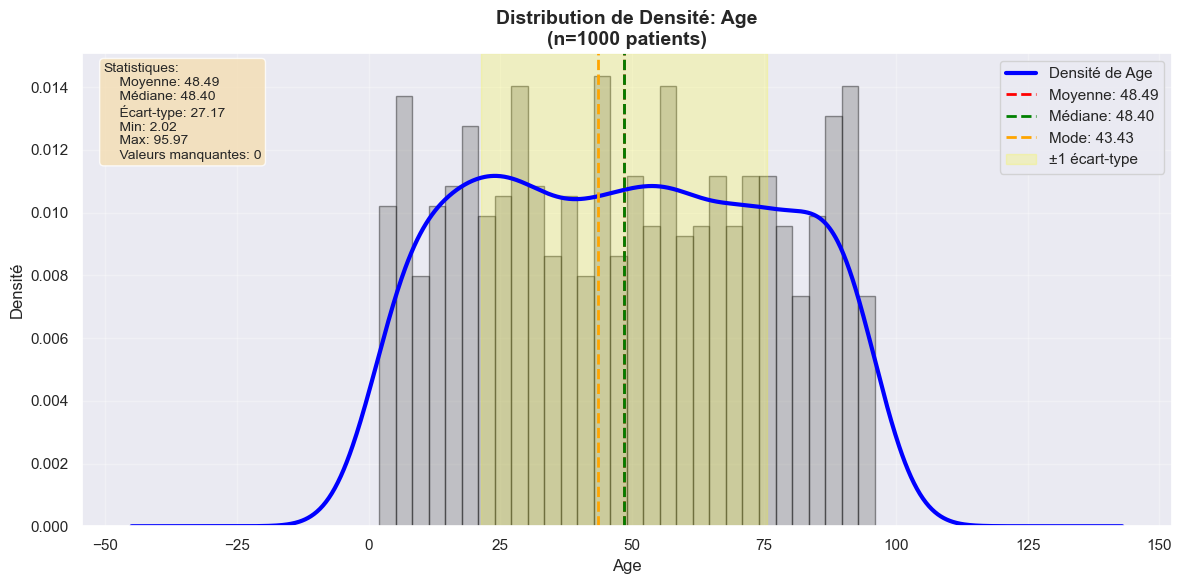

In [74]:

if variable_to_analyze:
    plt.figure(figsize=(12, 6))
    
    # Courbe de densité principale
    df[variable_to_analyze].plot(kind='density', linewidth=3, color='blue', 
                                 label=f'Densité de {variable_to_analyze}')
    
    # Ajouter l'histogramme en arrière-plan pour contexte
    df[variable_to_analyze].hist(bins=30, density=True, alpha=0.4, 
                                 color='gray', edgecolor='black')
    
    # Calculer les statistiques
    mean_val = df[variable_to_analyze].mean()
    median_val = df[variable_to_analyze].median()
    mode_val = df[variable_to_analyze].mode()[0] if not df[variable_to_analyze].mode().empty else None
    
    # Ajouter les lignes des statistiques
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, 
                label=f'Moyenne: {mean_val:.2f}')
    plt.axvline(median_val, color='green', linestyle='--', linewidth=2, 
                label=f'Médiane: {median_val:.2f}')
    
    if mode_val:
        plt.axvline(mode_val, color='orange', linestyle='--', linewidth=2, 
                    label=f'Mode: {mode_val:.2f}')
    
    # Zone de l'écart-type
    std_val = df[variable_to_analyze].std()
    plt.axvspan(mean_val - std_val, mean_val + std_val, 
                alpha=0.2, color='yellow', label='±1 écart-type')
    
    # Personnalisation
    plt.title(f'Distribution de Densité: {variable_to_analyze}\n(n={len(df)} patients)', 
              fontsize=14, fontweight='bold')
    plt.xlabel(variable_to_analyze, fontsize=12)
    plt.ylabel('Densité', fontsize=12)
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)
    
    # Ajouter des statistiques dans un coin
    stats_text = f"""Statistiques:
    Moyenne: {mean_val:.2f}
    Médiane: {median_val:.2f}
    Écart-type: {std_val:.2f}
    Min: {df[variable_to_analyze].min():.2f}
    Max: {df[variable_to_analyze].max():.2f}
    Valeurs manquantes: {df[variable_to_analyze].isnull().sum()}"""
    
    plt.text(0.02, 0.98, stats_text, transform=plt.gca().transAxes,
             verticalalignment='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.show()

## 3. Analyse des corrélations

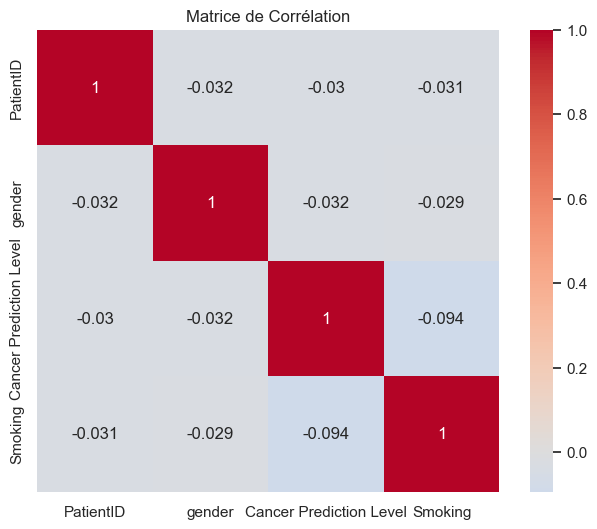

In [43]:
#Analyse multivariée
# Matrice de corrélation
correlation_matrix = df[['PatientID', 'gender', 'Cancer Prediction Level', 'Smoking']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True)
plt.title('Matrice de Corrélation')
plt.show()

## 4. Problèmes détectés

In [75]:
#Détection des problèmes dans le dataset
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calcul de l'IQR
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

# Détection des outliers
outliers = ((numeric_df < (Q1 - 1.5 * IQR)) | (numeric_df > (Q3 + 1.5 * IQR))).sum()
print("Nombre d'outliers par colonne :")
print(outliers)


Nombre d'outliers par colonne :
PatientID                   0
gender                      0
Obesity                     0
Smoking                     0
Genetic Risk                0
Cancer Prediction Level     0
Age                         0
missing_count              22
missing_percent            22
dtype: int64


In [76]:
#Colonnes constantes ou quasi constantes
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
constant_cols

['Obesity']

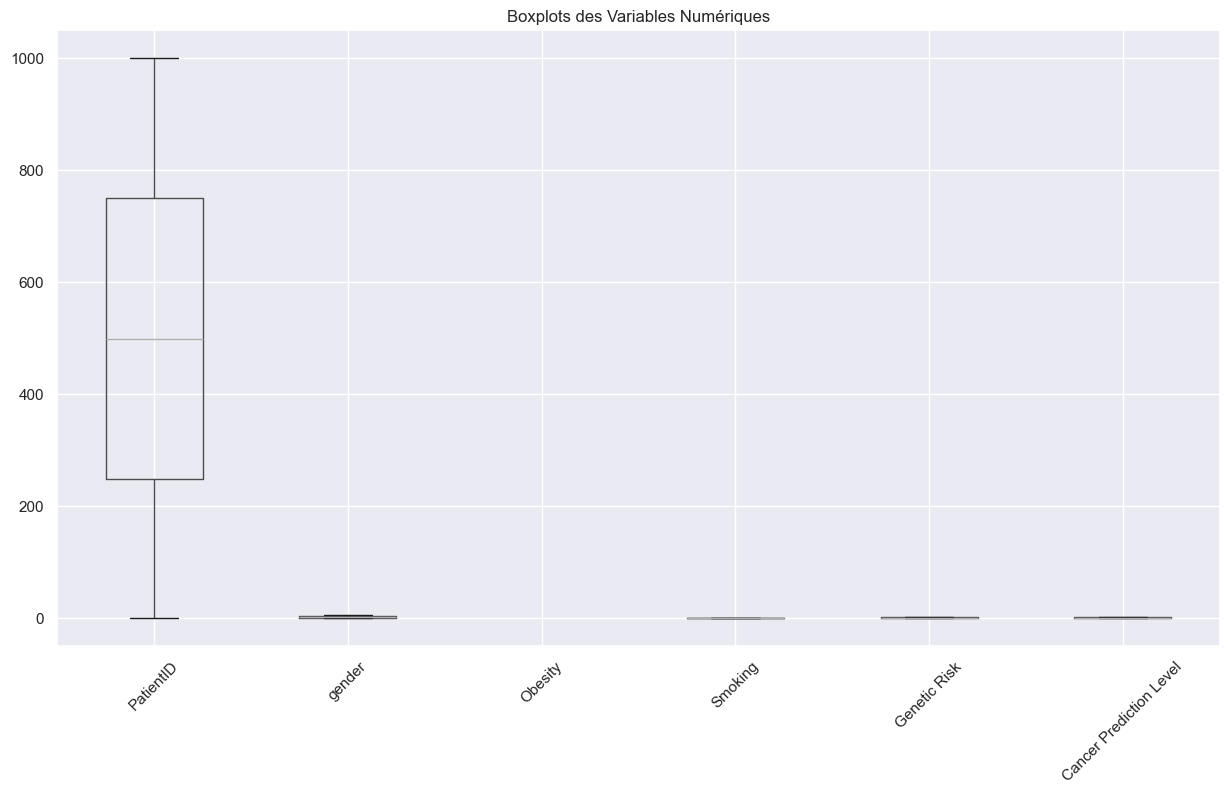

In [78]:
# Visualisation 4: Boxplots pour détecter les outliers
plt.figure(figsize=(15, 8))
df[numeric_cols[:6]].boxplot()
plt.title('Boxplots des Variables Numériques')
plt.xticks(rotation=45)
plt.show()



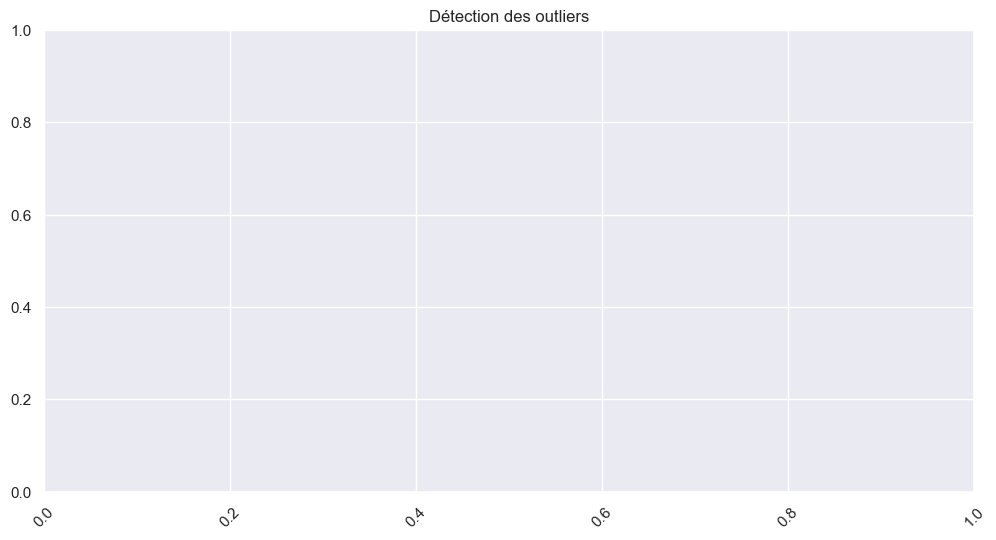

In [79]:
#Boxplot pour détecter les outliers
plt.figure(figsize=(12,6))
sns.boxplot(df=df.select_dtypes(include=np.number))
plt.title("Détection des outliers")
plt.xticks(rotation=45)
plt.show()


VISUALISATION 5: ANALYSE DES VALEURS ABERRANTES


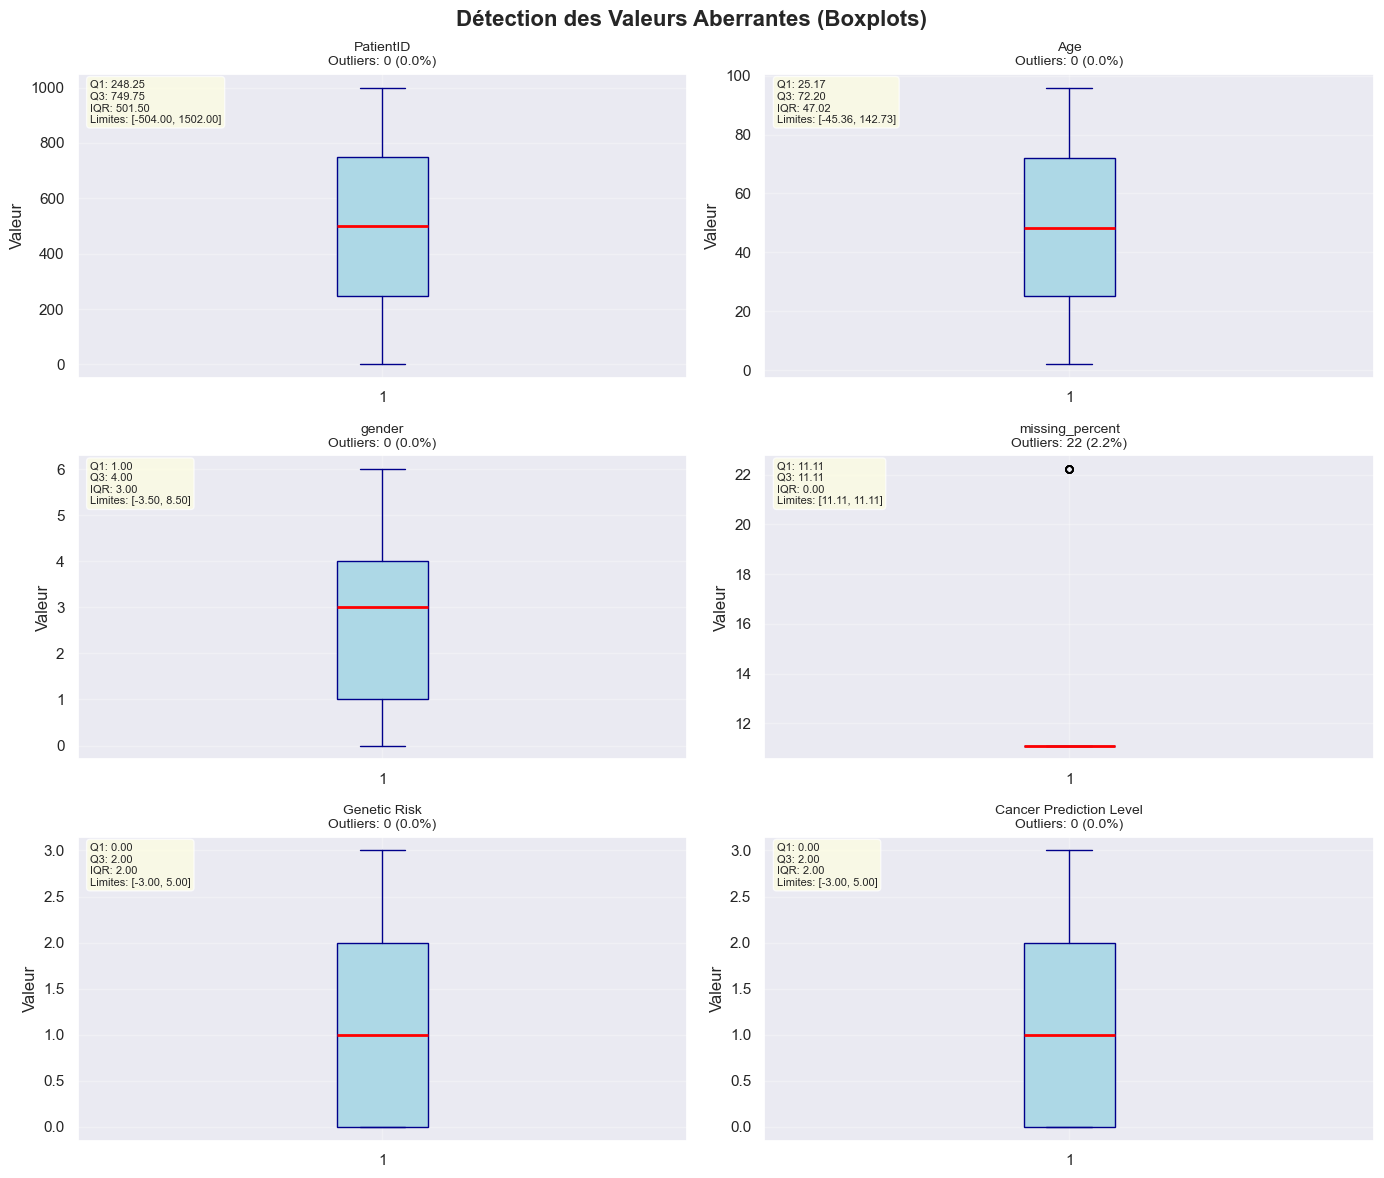


📋 Résumé des outliers par variable:
       Variable  Outliers Pourcentage  Min_Outlier  Max_Outlier
  missing_count        22        2.2%     2.000000     2.000000
missing_percent        22        2.2%    22.222222    22.222222


In [80]:
print("\n" + "=" * 80)
print("VISUALISATION 5: ANALYSE DES VALEURS ABERRANTES")
print("=" * 80)

# Sélectionner quelques variables numériques importantes
if len(numeric_cols) > 0:
    # Prendre les variables avec le plus de variance
    numeric_df = df[numeric_cols]
    var_series = numeric_df.var().sort_values(ascending=False)
    top_var_cols = var_series.head(min(6, len(var_series))).index.tolist()
    
    n_cols = 2
    n_rows = (len(top_var_cols) + 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
    axes = axes.flatten()
    
    for i, col in enumerate(top_var_cols):
        ax = axes[i]
        
        # Créer un boxplot
        boxplot = ax.boxplot(df[col].dropna(), patch_artist=True,
                            boxprops=dict(facecolor='lightblue', color='darkblue'),
                            medianprops=dict(color='red', linewidth=2),
                            whiskerprops=dict(color='darkblue'),
                            capprops=dict(color='darkblue'),
                            flierprops=dict(marker='o', color='red', alpha=0.5, markersize=5))
        
        # Calculer les outliers
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        outlier_percentage = (len(outliers) / len(df)) * 100
        
        ax.set_title(f'{col}\nOutliers: {len(outliers)} ({outlier_percentage:.1f}%)', fontsize=10)
        ax.set_ylabel('Valeur')
        
        # Ajouter une grille
        ax.grid(True, alpha=0.3)
        
        # Informations sur les outliers
        info_text = f"Q1: {Q1:.2f}\nQ3: {Q3:.2f}\nIQR: {IQR:.2f}\nLimites: [{lower_bound:.2f}, {upper_bound:.2f}]"
        ax.text(0.02, 0.98, info_text, transform=ax.transAxes, 
                fontsize=8, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))
    
    # Cacher les axes non utilisés
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle('Détection des Valeurs Aberrantes (Boxplots)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Résumé des outliers
    print("\n📋 Résumé des outliers par variable:")
    outlier_summary = []
    for col in numeric_cols[:10]:  # Limiter aux 10 premières pour la lisibilité
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        outlier_percentage = (len(outliers) / len(df)) * 100
        
        if len(outliers) > 0:
            outlier_summary.append({
                'Variable': col,
                'Outliers': len(outliers),
                'Pourcentage': f"{outlier_percentage:.1f}%",
                'Min_Outlier': outliers.min() if len(outliers) > 0 else None,
                'Max_Outlier': outliers.max() if len(outliers) > 0 else None
            })
    
    if outlier_summary:
        outlier_df = pd.DataFrame(outlier_summary)
        print(outlier_df.to_string(index=False))
    else:
        print("  Aucun outlier détecté dans les premières variables")